# Load cell calibration — method sensitivity analysis

Two calibration sessions at different temperatures (A: morning, B: midday). This notebook compares:

| | Method | What it does |
|---|---|---|
| **M1** | Single linear slope | `ADC = z + s·m`, least squares through the calibration nodes (variant: through *all* points) |
| **M2** | Piecewise (local) | Linear interpolation between the 0, 1, 2, 3, 4, 5 kg nodes |
| **T1** | Two-point temperature | Zero and slope temperature coefficients from session A vs B, applied to correct to reference conditions |
| **T2** | Overnight zero | Zero coefficient (counts/°C) from regressing the overnight no-load log on temperature |

Every interpolation method (M1/M2) is combined with every temperature treatment (none/T1/T2), then scored on the **test points** (ascending, descending, final checks) — never on the nodes used to fit.

**Scenarios**
- *In-session*: calibrate and test in the same session (A→A, B→B): best case, no temperature change.
- *Cross-session*: calibrate in one session, test in the other (A→B, B→A): what happens in the field when temperature moves.

⚠️ With only two temperatures, **T1 is fit *from* both sessions**, so its cross-session score is in-sample (it'll look perfect on zero by construction). **T2 is the honest out-of-sample test** of temperature compensation: its coefficient comes from independent overnight data.

In [1]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OVERNIGHT_CSV = "lys1.csv"     # <-- your overnight ADC-zero log (same format as the logger output)
TEMP_SOURCE   = "measured"       # "measured" or "expected": which session temperatures to use
LINEAR_FIT_ON = "nodes"          # "nodes" (0–5 kg nodes) or "all" (every point in the session) for M1

# Overnight regression options
OVERNIGHT_SKIP_HOURS = 0.0       # drop the first N hours (warm-up / settling)
OVERNIGHT_TIME_TERM  = False     # also fit a linear time trend, to separate creep/settling from temperature
TEMP_SPIKE_C         = 1.5       # °C jump from rolling median = temperature-sensor spike
ADC_SPIKE_MIN        = 300       # counts from rolling median = ADC glitch (~3 g)

# Field conditions for the sensitivity plots
FIELD_T_RANGE  = (14, 26)        # °C, expected range at the deployment site
TEMP_SENSOR_ERR = 0.5            # °C, DHT22 typical accuracy
EVAL_LOADS_G   = [0, 1000, 2000, 3000, 4000, 5000]

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## Data

In [2]:
sessions = {
    "A": {"label": "Morning (A)", "T_expected": 16.0, "T_measured": 17, "RH": 98},
    "B": {"label": "Midday (B)",  "T_expected": 24.0, "T_measured": 21, "RH": 98},
}
for k in sessions:
    sessions[k]["T"] = sessions[k][f"T_{TEMP_SOURCE}"]

raw = """step,phase,mass_g,A,B
ADC_zero initial,zero_initial,0,29704,30631
Node 1000,node,1000,129931,132486
Node 2000,node,2000,227531,230515
Node 3000,node,3000,328130,331594
Node 4000,node,4000,427609,431488
Node 5000,node,5000,530285,535499
Asc 300,asc,300,61185,61937
Asc 500,asc,500,80400,81373
Asc 1000,asc,1000,130809,132787
Asc 1500,asc,1500,179375,181178
Asc 2000,asc,2000,228337,230887
Asc 2500,asc,2500,280112,283244
Asc 3000,asc,3000,328827,332108
Asc 3500,asc,3500,381029,385040
Asc 4000,asc,4000,428176,431807
Asc 4500,asc,4500,478225,482731
Asc 5000,asc,5000,530882,536191
Desc 4500,desc,4500,478275,482839
Desc 4000,desc,4000,428302,432117
Desc 3500,desc,3500,381249,385231
Desc 3000,desc,3000,329083,332556
Desc 2500,desc,2500,280363,283507
Desc 2000,desc,2000,228629,231447
Desc 1500,desc,1500,179743,181641
Desc 1000,desc,1000,131189,133101
Desc 500,desc,500,80904,81754
Desc 300,desc,300,61801,62335
ADC_zero final,zero_final,0,31169,31369
Node 1000,node,1000,131193,133120
Node 2000,node,2000,228644,231341
Node 3000,node,3000,329082,332732
Node 4000,node,4000,428259,432553
Node 5000,node,5000,530981,536928
"""

wide = pd.read_csv(io.StringIO(raw))
data = wide.melt(id_vars=["step", "phase", "mass_g"], value_vars=["A", "B"],
                 var_name="session", value_name="adc")
data["T"] = data["session"].map(lambda s: sessions[s]["T"])

NODE_PHASES = ["zero_initial", "node"]
TEST_PHASES = ["asc", "desc", "zero_final", "final"]
pd.DataFrame(sessions).T

,label,T_expected,T_measured,RH,T
A,Morning (A),16.0,17,98,17
B,Midday (B),24.0,21,98,21


## 1. Data quality: the accuracy floor
Before comparing methods: hysteresis, repeatability and zero return set the limit no calibration method can beat. Converted to grams with each session's linear slope.

,slope (counts/g),max |hysteresis| (g),mean hysteresis desc−asc (g),max repeatability spread (g),median repeatability spread (g),zero return final−initial (g)
session,,,,,,
A,99.95,6.16,3.06,12.63,6.16,14.66
B,100.77,5.56,3.41,14.18,4.59,7.32


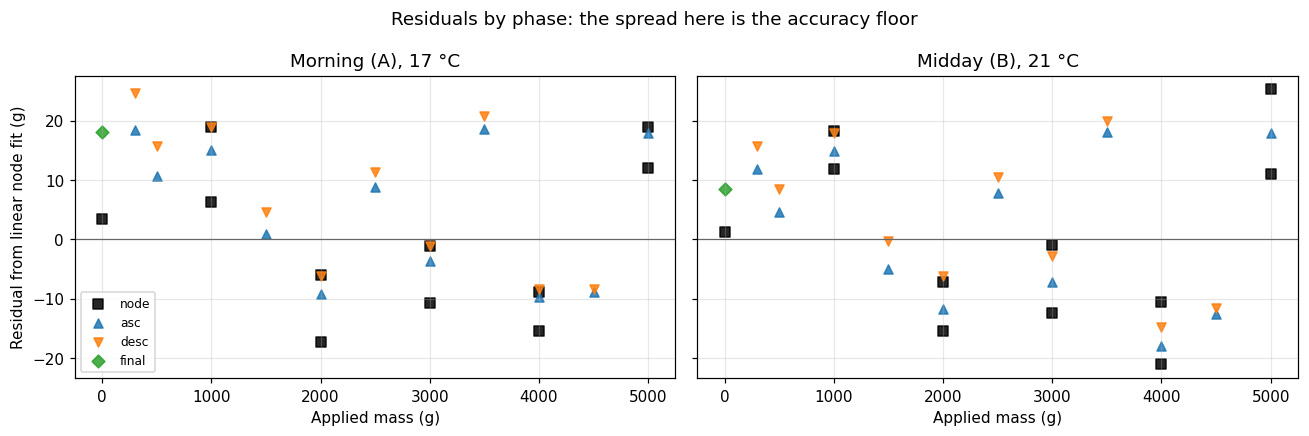

In [3]:
def nodes(session):
    return data[(data.session == session) & data.phase.isin(NODE_PHASES)].sort_values("mass_g")

quick_slope = {s: np.polyfit(nodes(s).mass_g, nodes(s).adc, 1)[0] for s in sessions}

rows = []
for s in sessions:
    d = data[data.session == s]
    k = quick_slope[s]
    asc  = d[d.phase == "asc"].set_index("mass_g").adc
    desc = d[d.phase == "desc"].set_index("mass_g").adc
    hyst = ((desc - asc).dropna() / k)
    # repeatability: spread of all readings at the same mass (node, asc, desc, final)
    rep = d[d.mass_g > 0].groupby("mass_g").adc.agg(lambda x: (x.max() - x.min()) / k)
    z0 = d[d.phase == "zero_initial"].adc.iloc[0]; z1 = d[d.phase == "zero_final"].adc.iloc[0]
    rows.append({"session": s, "slope (counts/g)": k,
                 "max |hysteresis| (g)": hyst.abs().max(),
                 "mean hysteresis desc−asc (g)": hyst.mean(),
                 "max repeatability spread (g)": rep.max(),
                 "median repeatability spread (g)": rep.median(),
                 "zero return final−initial (g)": (z1 - z0) / k})
quality = pd.DataFrame(rows).set_index("session")
display(quality.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, s in zip(axes, sessions):
    d = data[data.session == s]
    z, k = np.polyfit(nodes(s).mass_g, nodes(s).adc, 1)[::-1]
    for ph, mk, col in [("node", "s", "k"), ("asc", "^", "tab:blue"), ("desc", "v", "tab:orange"),
                        ("final", "D", "tab:green"), ("zero_initial", "s", "k"), ("zero_final", "D", "tab:green")]:
        dd = d[d.phase == ph]
        ax.scatter(dd.mass_g, (dd.adc - (z + k * dd.mass_g)) / k, marker=mk, color=col, s=35,
                   label=ph if ph not in ("zero_initial", "zero_final") else None, alpha=0.85)
    ax.axhline(0, color="0.4", lw=0.8)
    ax.set_title(f"{sessions[s]['label']}, {sessions[s]['T']} °C")
    ax.set_xlabel("Applied mass (g)")
axes[0].set_ylabel("Residual from linear node fit (g)")
axes[0].legend(fontsize=8)
fig.suptitle("Residuals by phase: the spread here is the accuracy floor")
fig.tight_layout(); plt.show()

## 2. Calibration models

In [4]:
class Calibration:
    """Calibration from one session. Maps ADC -> mass (g) at the session's reference temperature."""
    def __init__(self, session, fit_on=LINEAR_FIT_ON):
        self.session = session
        self.T_ref = sessions[session]["T"]
        n = nodes(session)
        fit_pts = n if fit_on == "nodes" else data[data.session == session]
        self.s, self.z = np.polyfit(fit_pts.mass_g, fit_pts.adc, 1)   # adc = z + s*m
        self.node_adc = n.adc.values.astype(float)
        self.node_m = n.mass_g.values.astype(float)

    def linear(self, adc):
        return (np.asarray(adc, float) - self.z) / self.s

    def piecewise(self, adc):
        adc = np.asarray(adc, float)
        xa, ym = self.node_adc, self.node_m
        m = np.interp(adc, xa, ym)
        # linear extrapolation beyond the end nodes using the end segments
        lo, hi = adc < xa[0], adc > xa[-1]
        m[lo] = ym[0] + (adc[lo] - xa[0]) * (ym[1] - ym[0]) / (xa[1] - xa[0])
        m[hi] = ym[-1] + (adc[hi] - xa[-1]) * (ym[-1] - ym[-2]) / (xa[-1] - xa[-2])
        return m

cal = {s: Calibration(s) for s in sessions}
cal_all = {s: Calibration(s, fit_on="all") for s in sessions}
pd.DataFrame({s: {"T_ref (°C)": c.T_ref, "zero z (counts)": c.z, "slope s (counts/g)": c.s}
              for s, c in cal.items()}).T.round(3)

,T_ref (°C),zero z (counts),slope s (counts/g)
A,17.0,29358.161,99.947
B,21.0,30515.226,100.774


## 3. Temperature coefficients

**T1: two-point.** From the fitted zero and slope of A and B:
`dz/dT = (z_B − z_A)/(T_B − T_A)`, `ds/dT = (s_B − s_A)/(T_B − T_A)`

**T2: overnight zero.** Regress the no-load overnight ADC on temperature (spikes and boot sample removed). This only gives the *zero* coefficient. The slope coefficient needs loaded data at two temperatures, so T2 is tested with ds/dT = 0, and as a hybrid with T1's slope coefficient.

In [5]:
TA, TB = sessions["A"]["T"], sessions["B"]["T"]
dzdT_2pt = (cal["B"].z - cal["A"].z) / (TB - TA)
dsdT_2pt = (cal["B"].s - cal["A"].s) / (TB - TA)

# --- overnight zero regression ---
dzdT_night, night = np.nan, None
if Path(OVERNIGHT_CSV).exists():
    night = pd.read_csv(OVERNIGHT_CSV, na_values=["NaN", "nan", ""])
    night["timestamp"] = pd.to_datetime(night["timestamp"])
    night = night.sort_values("timestamp").reset_index(drop=True)
    night["status"] = night["status"].fillna("")
    night["hours"] = (night.timestamp - night.timestamp.iloc[0]).dt.total_seconds() / 3600
    # 1) keep only rows logged without any error/boot flag
    ok = (night.status.str.strip() == "NO_CAL") & night.avg_raw_adc.notna() \
         & night.avg_temperature_C.notna() & (night.hours >= OVERNIGHT_SKIP_HOURS)
    # 2) temperature spikes (sun on the sensor): jump > TEMP_SPIKE_C from the rolling median
    T = night.avg_temperature_C
    t_spike = (T - T.rolling(5, center=True, min_periods=1).median()).abs() > TEMP_SPIKE_C
    # 3) ADC glitches: must exceed ADC_SPIKE_MIN counts from the rolling median of valid rows,
    #    so ordinary noise on a very stable night is not removed
    a = night.avg_raw_adc.where(ok)
    a_spike = (a - a.rolling(5, center=True, min_periods=1).median()).abs() > ADC_SPIKE_MIN
    night["use"] = ok & ~t_spike & ~a_spike
    print(f"Overnight filtering: {(~ok).sum()} flagged rows, {(ok & t_spike).sum()} temperature spikes, "
          f"{(ok & ~t_spike & a_spike).sum()} ADC glitches removed")
    n_ok = night[night.use]
    X = [n_ok.avg_temperature_C.values, np.ones(len(n_ok))]
    if OVERNIGHT_TIME_TERM:
        X.insert(1, n_ok.hours.values)
    coef, *_ = np.linalg.lstsq(np.column_stack(X), n_ok.avg_raw_adc.values, rcond=None)
    dzdT_night = coef[0]
    print(f"Overnight: {len(n_ok)} of {len(night)} samples used, "
          f"T range {n_ok.avg_temperature_C.min():.1f}–{n_ok.avg_temperature_C.max():.1f} °C, "
          f"absolute zero ≈ {n_ok.avg_raw_adc.median():.0f} counts")
    if len(n_ok) < 20 or n_ok.avg_temperature_C.max() - n_ok.avg_temperature_C.min() < 2:
        print("⚠️  Few samples or narrow temperature range: overnight coefficient is poorly constrained.")
else:
    print(f"⚠️  {OVERNIGHT_CSV} not found: T2 methods will be skipped.")

s_mean = (cal["A"].s + cal["B"].s) / 2
coefs = pd.DataFrame({
    "dz/dT (counts/°C)":      [dzdT_2pt, dzdT_night],
    "dz/dT (g/°C)":           [dzdT_2pt / s_mean, dzdT_night / s_mean],
    "ds/dT (counts/g/°C)":    [dsdT_2pt, np.nan],
    "ds/dT (ppm/°C)":         [dsdT_2pt / s_mean * 1e6, np.nan],
    "span error at 5 kg (g/°C)": [dsdT_2pt * 5000 / s_mean, np.nan],
}, index=["T1 two-point", "T2 overnight"])
coefs.round(3)

Overnight filtering: 0 flagged rows, 1 temperature spikes, 2 ADC glitches removed
Overnight: 50 of 53 samples used, T range 17.4–21.8 °C, absolute zero ≈ 31122 counts


,dz/dT (counts/°C),dz/dT (g/°C),ds/dT (counts/g/°C),ds/dT (ppm/°C),span error at 5 kg (g/°C)
T1 two-point,289.266,2.882,0.207,2060.098,10.3
T2 overnight,-188.103,-1.874,NaN,NaN,NaN


In [6]:
# ---- Zero coefficient from the overnight test: two-point (coldest vs warmest) ----
# Median ADC0 at the coldest and warmest overnight temperature.
# (The regression estimate, dzdT_night, is computed in the cell above.)
N_EXTREME = 1      # samples per end: the single coldest and single warmest reading

# Span coefficient: only obtainable from loaded data -> from the two calibration sessions
beta_span = dsdT_2pt

dzdT_ext = np.nan
if night is not None:
    used_n = night[night.use]
    if N_EXTREME == 1:
        # temperature is logged at 0.1 °C, so several readings can share the extreme value:
        # use all readings at the minimum and at the maximum temperature
        cold = used_n[used_n.avg_temperature_C == used_n.avg_temperature_C.min()]
        warm = used_n[used_n.avg_temperature_C == used_n.avg_temperature_C.max()]
    else:
        n_sorted = used_n.sort_values("avg_temperature_C", kind="stable")
        cold, warm = n_sorted.head(N_EXTREME), n_sorted.tail(N_EXTREME)
    k = f"{len(cold)}/{len(warm)}"
    T_cold, T_warm = cold.avg_temperature_C.median(), warm.avg_temperature_C.median()
    z_cold, z_warm = cold.avg_raw_adc.median(), warm.avg_raw_adc.median()
    if T_warm - T_cold > 0:
        dzdT_ext = (z_warm - z_cold) / (T_warm - T_cold)

    display(pd.DataFrame({
        "T (°C)": [T_cold, T_warm],
        "ADC zero": [z_cold, z_warm],
        "time span": [f"{cold.timestamp.min():%m-%d %H:%M} – {cold.timestamp.max():%m-%d %H:%M}",
                      f"{warm.timestamp.min():%m-%d %H:%M} – {warm.timestamp.max():%m-%d %H:%M}"],
    }, index=[f"coldest ({len(cold)} readings)", f"warmest ({len(warm)} readings)"]).round(2))

print("Temperature coefficients:")
for name, v in [("α overnight regression", dzdT_night), ("α overnight two-point", dzdT_ext)]:
    print(f"  {name:24s} {v:+8.1f} counts/°C = {v / s_mean:+.2f} g/°C")
print(f"  {'β span (sessions)':24s} {beta_span / s_mean * 1e6:+8.0f} ppm/°C")

,T (°C),ADC zero,time span
coldest (2 readings),17.4,31249.5,10-16 05:48 – 10-16 06:48
warmest (2 readings),21.8,30489.5,10-15 14:12 – 10-15 14:26


Temperature coefficients:
  α overnight regression     -188.1 counts/°C = -1.87 g/°C
  α overnight two-point      -172.7 counts/°C = -1.72 g/°C
  β span (sessions)           +2060 ppm/°C


## 4. Temperature correction
Every temperature model is applied the same way: estimate zero and slope at the reading's temperature, then map the ADC back to the calibration's reference conditions before applying M1 or M2:

`z(T) = z_ref + dz/dT·(T − T_ref)`, `s(T) = s_ref + ds/dT·(T − T_ref)`
`ADC_ref = z_ref + (ADC − z(T)) · s_ref / s(T)`

This way piecewise calibration gets the same correction as linear.

Regression: α = -188.1 counts/°C, r = -0.961, R² = 0.924, residual RMSE = 72 counts (0.7 g), n = 50
Two-point:  α = -172.7 counts/°C, R² on all overnight data = 0.883, residual RMSE = 89 counts (0.9 g)


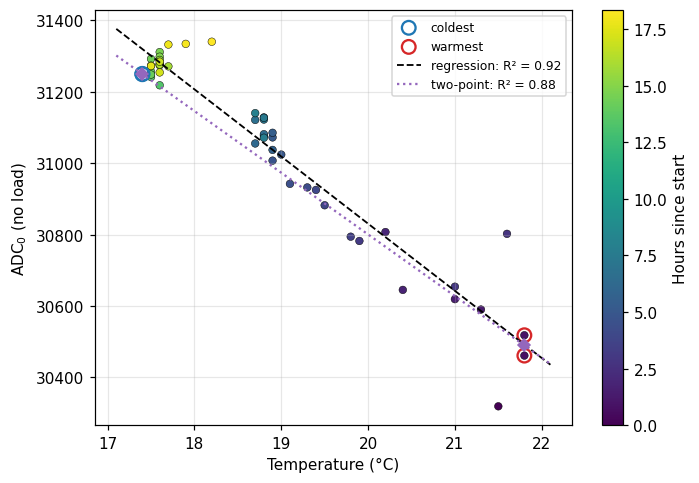

In [7]:
if night is not None:
    used = night[night.use]
    Tn, Zn = used.avg_temperature_C.values, used.avg_raw_adc.values
    ss_tot = ((Zn - Zn.mean())**2).sum()

    def fit_stats(slope, intercept):
        res = Zn - (intercept + slope * Tn)
        return 1 - (res**2).sum() / ss_tot, np.sqrt((res**2).mean())

    r = np.corrcoef(Tn, Zn)[0, 1]
    b0 = Zn.mean() - dzdT_night * Tn.mean()
    r2_reg, rmse_reg = fit_stats(dzdT_night, b0)
    print(f"Regression: α = {dzdT_night:.1f} counts/°C, r = {r:.3f}, R² = {r2_reg:.3f}, "
          f"residual RMSE = {rmse_reg:.0f} counts ({rmse_reg / s_mean:.1f} g), n = {len(used)}")

    if np.isfinite(dzdT_ext):
        b1 = z_cold - dzdT_ext * T_cold          # line through the two extreme points
        r2_2pt, rmse_2pt = fit_stats(dzdT_ext, b1)
        print(f"Two-point:  α = {dzdT_ext:.1f} counts/°C, R² on all overnight data = {r2_2pt:.3f}, "
              f"residual RMSE = {rmse_2pt:.0f} counts ({rmse_2pt / s_mean:.1f} g)")

    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    sc = ax.scatter(Tn, Zn, c=used.hours, cmap="viridis", s=25, edgecolor="k", lw=0.3)
    fig.colorbar(sc, ax=ax, label="Hours since start")
    # highlight the samples used for the two-point estimate
    ax.scatter(cold.avg_temperature_C, cold.avg_raw_adc, s=80, facecolors="none",
               edgecolors="tab:blue", lw=1.5, label="coldest")
    ax.scatter(warm.avg_temperature_C, warm.avg_raw_adc, s=80, facecolors="none",
               edgecolors="tab:red", lw=1.5, label="warmest")
    tx = np.linspace(Tn.min() - 0.3, Tn.max() + 0.3, 20)
    ax.plot(tx, b0 + dzdT_night * tx, "k--", lw=1.2,
            label=f"regression: R² = {r2_reg:.2f}")
    if np.isfinite(dzdT_ext):
        ax.plot(tx, b1 + dzdT_ext * tx, ":", color="tab:purple", lw=1.5,
                label=f"two-point: R² = {r2_2pt:.2f}")
        ax.plot([T_cold, T_warm], [z_cold, z_warm], "D", color="tab:purple", ms=6)
    ax.set_xlabel("Temperature (°C)"); ax.set_ylabel("ADC$_0$ (no load)")
    ax.legend(fontsize=8); fig.tight_layout(); plt.show()

In [8]:
# Temperature corrections compared (α: zero coefficient, β: span coefficient)
TEMP_MODELS = {"None": (0.0, 0.0)}
if np.isfinite(dzdT_night):
    TEMP_MODELS["Overnight regression"] = (dzdT_night, 0.0)
if np.isfinite(dzdT_ext):
    TEMP_MODELS["Overnight two-point"] = (dzdT_ext, 0.0)
if np.isfinite(dzdT_night):
    TEMP_MODELS["Overnight regression + span"] = (dzdT_night, beta_span)
if np.isfinite(dzdT_ext):
    TEMP_MODELS["Overnight two-point + span"] = (dzdT_ext, beta_span)

def in_sample(temp_model, scenario):
    """β comes from the calibration sessions, so span-corrected models are partly
    in-sample in the cross-session comparison."""
    return scenario == "cross-session" and "span" in temp_model

def to_ref(adc, T, c, dzdT, dsdT):
    dT = np.asarray(T, float) - c.T_ref
    zT, sT = c.z + dzdT * dT, c.s + dsdT * dT
    return c.z + (np.asarray(adc, float) - zT) * c.s / sT

INTERP = {
    "Linear (all points)": None,   # handled via cal_all
    "Linear (nodes)": None,
    "Piecewise": None,
}

def predict(interp, cal_s, adc, T, temp_model):
    dzdT, dsdT = TEMP_MODELS[temp_model]
    c = cal_all[cal_s] if interp == "Linear (all points)" else cal[cal_s]
    a = to_ref(adc, T, c, dzdT, dsdT)
    return c.piecewise(a) if interp == "Piecewise" else c.linear(a)

## 5. Evaluate all combinations

In [9]:
tests = data[data.phase.isin(TEST_PHASES)]
records = []
for interp in INTERP:
    for tm in TEMP_MODELS:
        for cs in sessions:
            for ts in sessions:
                t = tests[tests.session == ts]
                err = predict(interp, cs, t.adc.values, t["T"].values, tm) - t.mass_g.values
                for (_, r), e in zip(t.iterrows(), err):
                    records.append({"interp": interp, "temp_model": tm, "cal": cs, "test": ts,
                                    "scenario": "in-session" if cs == ts else "cross-session",
                                    "phase": r.phase, "mass_g": r.mass_g, "error_g": e})
res = pd.DataFrame(records)

def metrics(e):
    e = np.asarray(e, float)
    rmse = np.sqrt((e**2).mean())
    return {"RMSE (g)": rmse, "max |err| (g)": np.abs(e).max(),
            "bias (g)": e.mean(), "RMSE % FS": rmse / 50}

keys = ["scenario", "temp_model", "interp"]
summary = pd.DataFrame.from_dict(
    {k: metrics(g["error_g"]) for k, g in res.groupby(keys)}, orient="index")
summary.index = pd.MultiIndex.from_tuples(summary.index, names=keys)
# flag combos whose temperature coefficients were fitted using the test session
summary["in-sample?"] = [in_sample(tm, sc) for sc, tm, _ in summary.index]
summary.round(2)

RMSE (g)  \
scenario      temp_model                  interp                          
cross-session None                        Linear (all points)     32.55   
                                          Linear (nodes)          34.05   
                                          Piecewise               30.75   
              Overnight regression        Linear (all points)     39.09   
                                          Linear (nodes)          40.56   
                                          Piecewise               37.20   
              Overnight regression + span Linear (all points)     19.34   
                                          Linear (nodes)          21.40   
                                          Piecewise               19.37   
              Overnight two-point         Linear (all points)     38.54   
                                          Linear (nodes)          40.02   
                                          Piecewise               36.66   
              Overnight two-point + span  Linear (all points)     18.83   
                                          Linear (nodes)          20.92   
                                          Piecewise               18.91   
in-session    None                        Linear (all points)     10.93   
                                          Linear (nodes)          12.97   
                                          Piecewise               12.32   
              Overnight regression        Linear (all points)     10.93   
                                          Linear (nodes)          12.97   
                                          Piecewise               12.32   
              Overnight regression + span Linear (all points)     10.93   
                                          Linear (nodes)          12.97   
                                          Piecewise               12.32   
              Overnight two-point         Linear (all points)     10.93   
                                          Linear (nodes)          12.97   
                                          Piecewise               12.32   
              Overnight two-point + span  Linear (all points)     10.93   
                                          Linear (nodes)          12.97   
                                          Piecewise               12.32   

                                                               max |err| (g)  \
scenario      temp_model                  interp                               
cross-session None                        Linear (all points)          73.46   
                                          Linear (nodes)               71.02   
                                          Piecewise                    69.88   
              Overnight regression        Linear (all points)          81.00   
                                          Linear (nodes)               78.55   
                                          Piecewise                    77.52   
              Overnight regression + span Linear (all points)          39.20   
                                          Linear (nodes)               38.86   
                                          Piecewise                    47.82   
              Overnight two-point         Linear (all points)          80.39   
                                          Linear (nodes)               77.93   
                                          Piecewise                    76.90   
              Overnight two-point + span  Linear (all points)          38.59   
                                          Linear (nodes)               38.25   
                                          Piecewise                    47.20   
in-session    None                        Linear (all points)          20.98   
                                          Linear (nodes)               24.60   
                                          Piecewise                    31.60   
              Overnight regression        Linear (all points) 

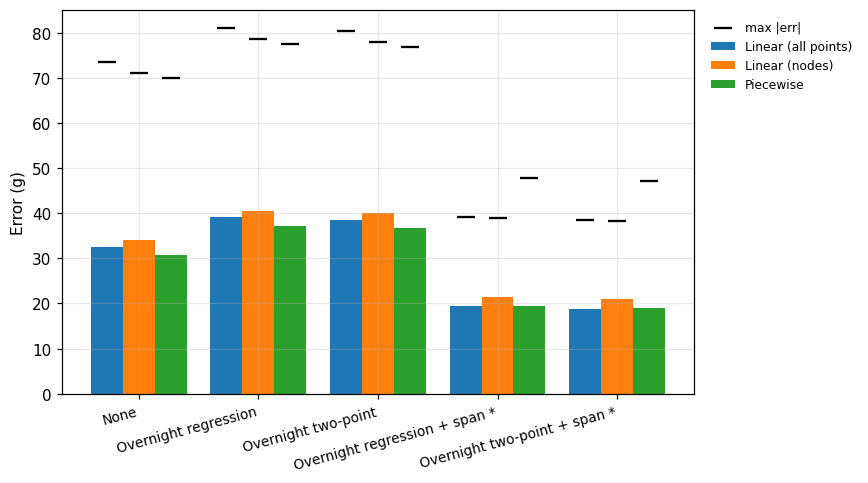

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sc = "cross-session"
temp_order = list(TEMP_MODELS)
interp_order = list(INTERP)
colors = plt.cm.tab10.colors
w = 0.8 / len(interp_order)

for i, ip in enumerate(interp_order):
    vals = [summary.loc[(sc, tm, ip), "RMSE (g)"] for tm in temp_order]
    mx = [summary.loc[(sc, tm, ip), "max |err| (g)"] for tm in temp_order]
    x = np.arange(len(temp_order)) + (i - (len(interp_order) - 1) / 2) * w
    ax.bar(x, vals, w, color=colors[i], label=ip)
    ax.scatter(x, mx, marker="_", s=150, color="k", zorder=3,
               label="max |err|" if i == 0 else None)

ax.set_xticks(np.arange(len(temp_order)))
ax.set_xticklabels([t + (" *" if in_sample(t, sc) else "") for t in temp_order],
                   rotation=15, ha="right", fontsize=9)
ax.set_ylabel("Error (g)")

ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
fig.tight_layout(); plt.show()

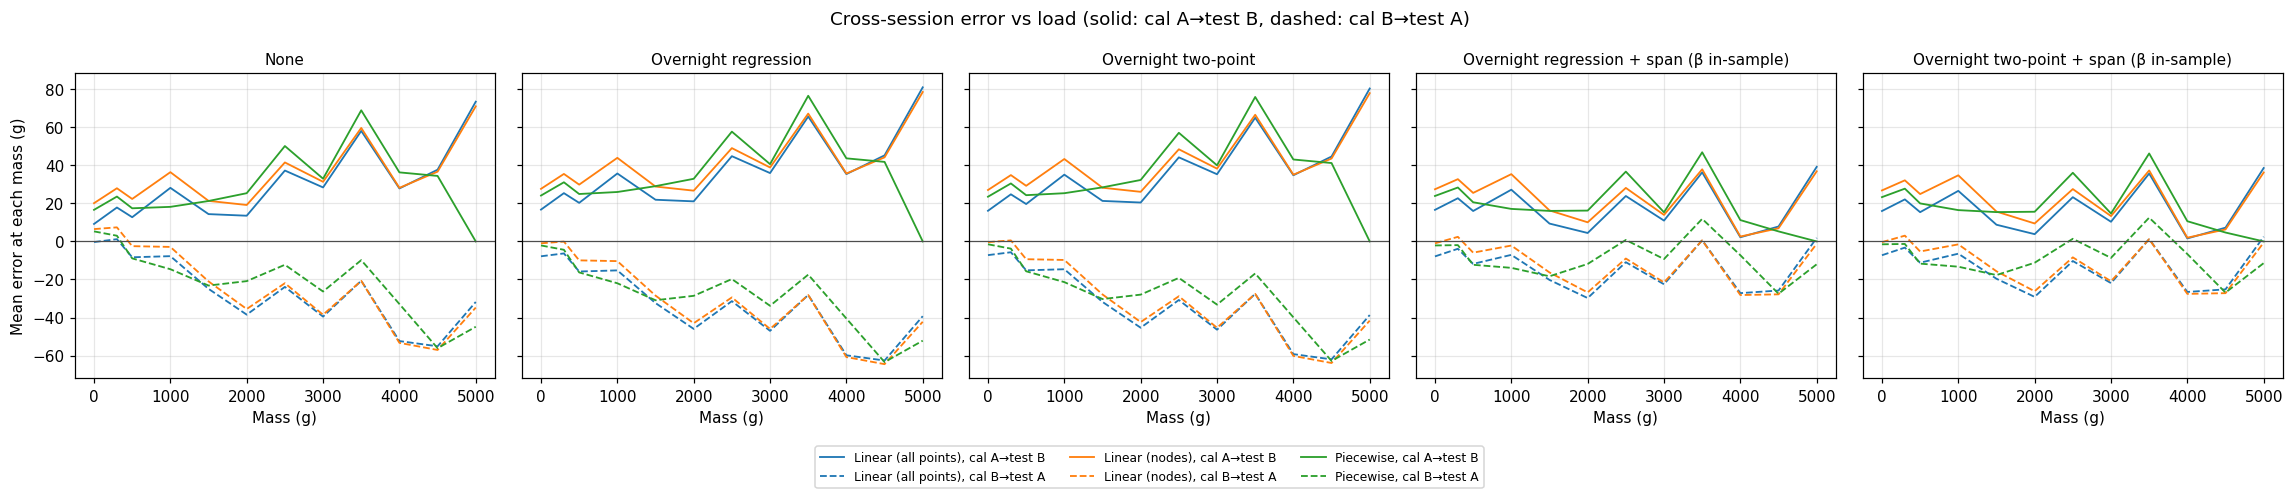

In [11]:
# Error vs mass for every combination, cross-session (the field-relevant case)
fig, axes = plt.subplots(1, len(temp_order), figsize=(4.2 * len(temp_order), 4), sharey=True)
axes = np.atleast_1d(axes)
mk = {"asc": "^", "desc": "v", "final": "D", "zero_final": "o"}
for ax, tm in zip(axes, temp_order):
    for i, ip in enumerate(interp_order):
        for dirn, ls in [(("A", "B"), "-"), (("B", "A"), "--")]:
            g = res[(res.interp == ip) & (res.temp_model == tm) & (res.cal == dirn[0]) & (res.test == dirn[1])]
            gm = g.groupby("mass_g").error_g.mean()
            ax.plot(gm.index, gm.values, ls, color=colors[i], lw=1.2,
                    label=f"{ip}, cal {dirn[0]}→test {dirn[1]}" if tm == temp_order[0] else None)
    ax.axhline(0, color="0.3", lw=0.8)
    ax.set_title(tm + (" (β in-sample)" if "span" in tm else ""), fontsize=10)
    ax.set_xlabel("Mass (g)")
axes[0].set_ylabel("Mean error at each mass (g)")
fig.legend(loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.12))
fig.suptitle("Cross-session error vs load (solid: cal A→test B, dashed: cal B→test A)")
fig.tight_layout(); plt.show()

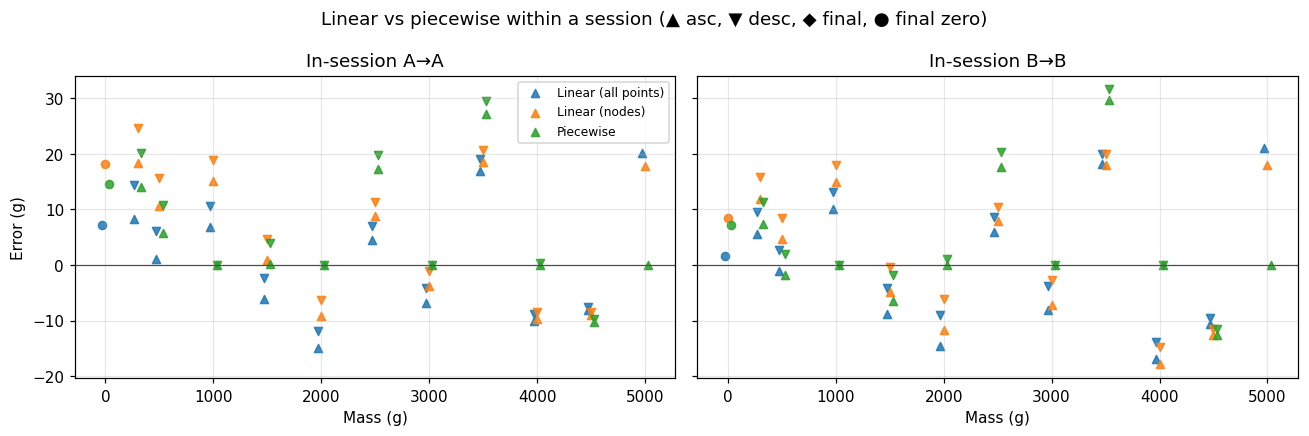

In [12]:
# In-session: linear vs piecewise, the pure interpolation question (no temperature involved)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, s in zip(axes, sessions):
    for i, ip in enumerate(interp_order):
        g = res[(res.interp == ip) & (res.temp_model == "None") & (res.cal == s) & (res.test == s)]
        for ph, m in mk.items():
            gg = g[g.phase == ph]
            ax.scatter(gg.mass_g + (i - 1) * 30, gg.error_g, marker=m, color=colors[i], s=28,
                       label=ip if ph == "asc" else None, alpha=0.85)
    ax.axhline(0, color="0.3", lw=0.8)
    ax.set_title(f"In-session {s}→{s}"); ax.set_xlabel("Mass (g)")
axes[0].set_ylabel("Error (g)"); axes[0].legend(fontsize=8)
fig.suptitle("Linear vs piecewise within a session (▲ asc, ▼ desc, ◆ final, ● final zero)")
fig.tight_layout(); plt.show()

## 6. Sensitivity to temperature

**(a) Uncompensated error vs temperature.** If you calibrate once at T_ref and don't correct, how far off are you across the field temperature range? Shown for both the two-point and the overnight coefficient.

**(b) Sensitivity to temperature *measurement* error.** With compensation, a temperature reading that's off by δT gives a mass error of `(dz/dT + m·ds/dT)·δT / s`. That tells you whether the DHT is accurate enough to compensate with.

**(c) Expected vs measured session temperatures.** How much the coefficients change depending on which temperatures you assume.

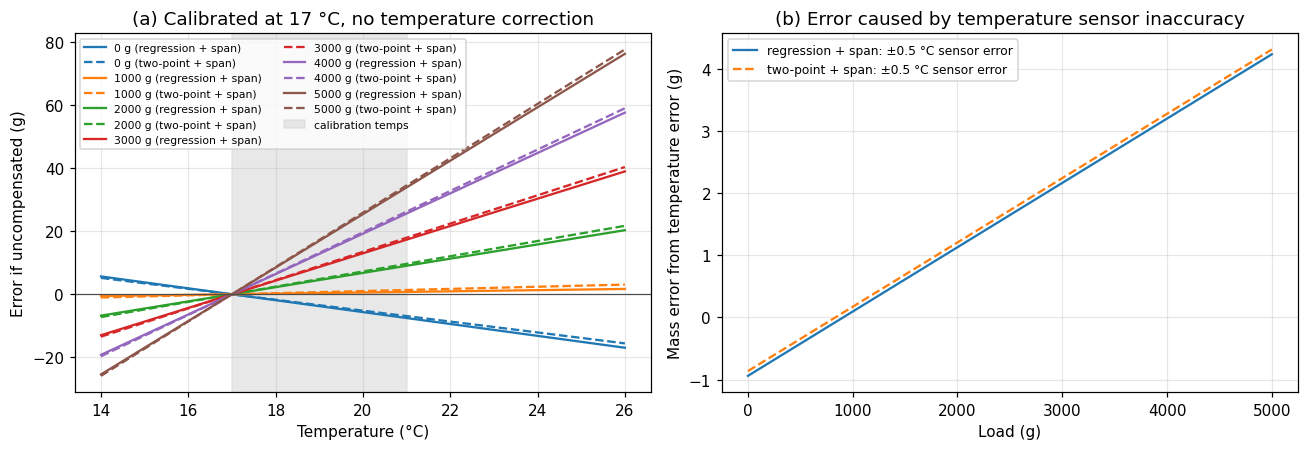

In [13]:
c = cal["A"]
Ts = np.linspace(*FIELD_T_RANGE, 100)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
for j, m in enumerate(EVAL_LOADS_G):
    for name, (dz, ds), ls in [("regression + span", (dzdT_night, beta_span), "-"),
                           ("two-point + span", (dzdT_ext, beta_span), "--")]:
        if not np.isfinite(dz):
            continue
        dT = Ts - c.T_ref
        adc_true = (c.z + dz * dT) + (c.s + ds * dT) * m
        ax.plot(Ts, c.linear(adc_true) - m, ls, color=colors[j],
                label=f"{m} g ({name})")
ax.axvspan(min(TA, TB), max(TA, TB), color="0.85", alpha=0.6, label="calibration temps")
ax.axhline(0, color="0.3", lw=0.8)
ax.set_xlabel("Temperature (°C)"); ax.set_ylabel("Error if uncompensated (g)")
ax.set_title(f"(a) Calibrated at {c.T_ref} °C, no temperature correction")
ax.legend(fontsize=7, ncol=2)

ax = axes[1]
ms = np.linspace(0, 5000, 50)
for name, (dz, ds), ls in [("regression + span", (dzdT_night, beta_span), "-"),
                           ("two-point + span", (dzdT_ext, beta_span), "--")]:
    if not np.isfinite(dz):
        continue
    g_per_degC = (dz + ms * ds) / c.s
    ax.plot(ms, g_per_degC * TEMP_SENSOR_ERR, ls, lw=1.5, label=f"{name}: ±{TEMP_SENSOR_ERR} °C sensor error")
ax.set_xlabel("Load (g)"); ax.set_ylabel("Mass error from temperature error (g)")
ax.set_title("(b) Error caused by temperature sensor inaccuracy")
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 7. Summary

In [14]:
best_in = summary.xs("in-session")["RMSE (g)"].idxmin()
cross = summary.xs("cross-session")
oos = cross[~cross["in-sample?"]]
best_oos = oos["RMSE (g)"].idxmin()
base = cross.loc[("None", "Linear (nodes)")]

print(f"Accuracy floor (hysteresis/repeatability): max spread "
      f"{quality['max repeatability spread (g)'].max():.1f} g, max hysteresis {quality['max |hysteresis| (g)'].max():.1f} g")
print(f"Best in-session:   {best_in[1]} → RMSE {summary.loc[('in-session',)+best_in,'RMSE (g)']:.2f} g")
print(f"Linear vs piecewise in-session (no T): "
      f"{summary.loc[('in-session','None','Linear (nodes)'),'RMSE (g)']:.2f} vs "
      f"{summary.loc[('in-session','None','Piecewise'),'RMSE (g)']:.2f} g RMSE")
print(f"Cross-session, uncompensated linear: RMSE {base['RMSE (g)']:.2f} g, max {base['max |err| (g)']:.2f} g")
print(f"Best honest cross-session (T coefficient not fit on test data): {best_oos} → "
      f"RMSE {oos.loc[best_oos,'RMSE (g)']:.2f} g, max {oos.loc[best_oos,'max |err| (g)']:.2f} g")
print(f"Zero tempco: overnight regression {dzdT_night/s_mean:+.2f} g/°C vs overnight two-point {dzdT_ext/s_mean:+.2f} g/°C")

Accuracy floor (hysteresis/repeatability): max spread 14.2 g, max hysteresis 6.2 g
Best in-session:   Linear (all points) → RMSE 10.93 g
Linear vs piecewise in-session (no T): 12.97 vs 12.32 g RMSE
Cross-session, uncompensated linear: RMSE 34.05 g, max 71.02 g
Best honest cross-session (T coefficient not fit on test data): ('None', 'Piecewise') → RMSE 30.75 g, max 69.88 g
Zero tempco: overnight regression -1.87 g/°C vs overnight two-point -1.72 g/°C
